<a href="https://colab.research.google.com/github/Rickylel/AF3_Aplicacion_de_Clustering/blob/main/AF3_Aplicacion_de_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Fundamental 3: Aplicación de Clustering (K-Means)
**Dataset:** Stroke Prediction Dataset (Kaggle), versión limpia obtenida en la Actividad Fundamental 1 (`Dataset_limpio.csv`).

**Objetivo general:** agrupar a los pacientes en perfiles usando **aprendizaje no supervisado** (K-Means), sin que el algoritmo conozca la variable `stroke`, y después comprobar si alguno de los grupos descubiertos concentra a los pacientes de alto riesgo.

**Contenido**
1. Preparación y escalado de características
2. Búsqueda del número óptimo de clústeres (codo y silueta)
3. Entrenamiento del modelo y visualización de centroides
4. Validación cruzada con la etiqueta real `stroke`

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

---
## Sección 1: Preparación y escalado de características para distancias
### 1.1 Cargar el dataset limpio y separar la variable objetivo
Guardamos `stroke` en una variable aparte **antes** de quitarla, para usarla únicamente en la Sección 4. El modelo nunca la verá.
La columna `id` ya se había eliminado en la Actividad 1, el código la quita solo si existe.

In [ ]:
df = pd.read_csv('Dataset_limpio.csv')
print('Dimensiones del dataset limpio:', df.shape)
df.head()

Dimensiones del dataset limpio: (5109, 18)


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,0,1,0,0
1,0,61.0,0,0,1,0,202.21,28.1,1,0,0,0,1,0,0,0,1,0
2,1,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,0,1,0
3,0,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,0,1
4,0,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,0,1,0


In [ ]:
# Guardar la etiqueta real para la validación final
y_stroke = df['stroke'].copy()

# Eliminar la variable objetivo y el id (si existiera)
df_features = df.drop(columns=['stroke', 'id'], errors='ignore')

print('Columnas restantes:', df_features.shape[1])
print('¿stroke sigue en el DataFrame?', 'stroke' in df_features.columns)
print('Casos de stroke guardados aparte:', y_stroke.sum(), 'de', len(y_stroke))

Columnas restantes: 17
¿stroke sigue en el DataFrame? False
Casos de stroke guardados aparte: 249 de 5109


### 1.2 Selección de variables numéricas continuas
K-Means agrupa por **distancia euclidiana**, por lo que funciona mejor con variables continuas. Las columnas binarias y dummies (0/1) generan distancias "en escalón" que dominan la forma de los grupos sin aportar un perfil clínico interpretable, así que usamos las tres variables continuas clave:

| Variable | Unidad | Significado |
|---|---|---|
| `age` | años | Edad del paciente |
| `avg_glucose_level` | mg/dL | Nivel promedio de glucosa en sangre |
| `bmi` | kg/m² | Índice de masa corporal |

In [ ]:
features = ['age', 'avg_glucose_level', 'bmi']
X = df_features[features].copy()
X.describe().round(2)

,age,avg_glucose_level,bmi
count,5109.00,5109.00,5109.00
mean,43.23,106.14,28.86
std,22.61,45.29,7.70
min,0.08,55.12,10.30
25%,25.00,77.24,23.80
50%,45.00,91.88,28.10
75%,61.00,114.09,32.80
max,82.00,271.74,97.60


In [ ]:
# Rango de cada variable: se ve que las escalas son muy distintas
rangos = pd.DataFrame({'mínimo': X.min(), 'máximo': X.max(),
                       'rango': X.max() - X.min(), 'desv. estándar': X.std()}).round(2)
rangos

,mínimo,máximo,rango,desv. estándar
age,0.08,82.00,81.92,22.61
avg_glucose_level,55.12,271.74,216.62,45.29
bmi,10.30,97.60,87.30,7.70


### 1.3 Escalado con `StandardScaler`
`StandardScaler` transforma cada variable con la fórmula

$$z = \frac{x - \mu}{\sigma}$$

de modo que todas quedan con **media 0 y desviación estándar 1**, es decir, en la misma escala.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.describe().round(2)

,age,avg_glucose_level,bmi
count,5109.00,5109.00,5109.00
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.41
25%,-0.81,-0.64,-0.66
50%,0.08,-0.31,-0.10
75%,0.79,0.18,0.51
max,1.71,3.66,8.93


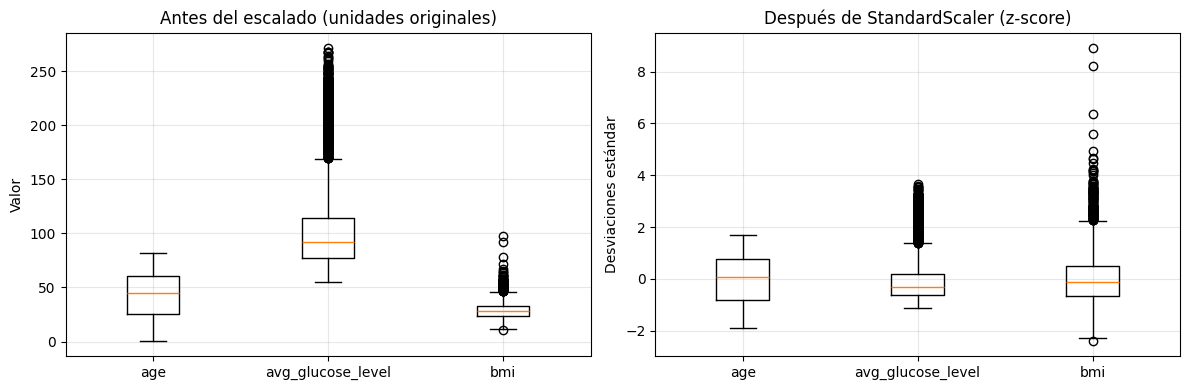

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([X[c] for c in features])
axes[0].set_xticks([1, 2, 3], features)
axes[0].set_title('Antes del escalado (unidades originales)')
axes[0].set_ylabel('Valor')
axes[1].boxplot([X_scaled_df[c] for c in features])
axes[1].set_xticks([1, 2, 3], features)
axes[1].set_title('Después de StandardScaler (z-score)')
axes[1].set_ylabel('Desviaciones estándar')
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.4 Investigación: ¿por qué K-Means falla sin escalar?
K-Means asigna cada punto al centroide más cercano usando la **distancia euclidiana**:

$$d(p, c) = \sqrt{(edad_p - edad_c)^2 + (glucosa_p - glucosa_c)^2 + (bmi_p - bmi_c)^2}$$

Cada término se suma **en sus unidades originales**. La edad va de 0 a 82 años (σ ≈ 22.6), mientras que la glucosa va de 55 a 272 mg/dL (σ ≈ 45.3). Una diferencia "normal" en glucosa (≈ 45 mg/dL) pesa en la suma igual que una diferencia de 45 años de edad, que es enorme. Al elevar al cuadrado, la variable con mayor rango **domina** la distancia y las demás prácticamente desaparecen.

Consecuencias:
- El algoritmo termina agrupando casi solo por glucosa: los clústeres son "rebanadas" del eje de glucosa e ignoran la edad, que es el factor de riesgo más importante.
- El resultado depende de la **unidad de medida** elegida (si la glucosa se midiera en mmol/L, que es ≈ 18 veces más pequeño, el resultado cambiaría por completo), lo cual no tiene sentido físico.
- La inercia y la silueta quedan dominadas por una sola variable, así que también se elige mal el número de clústeres.

Al estandarizar, cada variable aporta en proporción a cuántas **desviaciones estándar** se aleja de la media, no a sus unidades. Lo comprobamos experimentalmente:

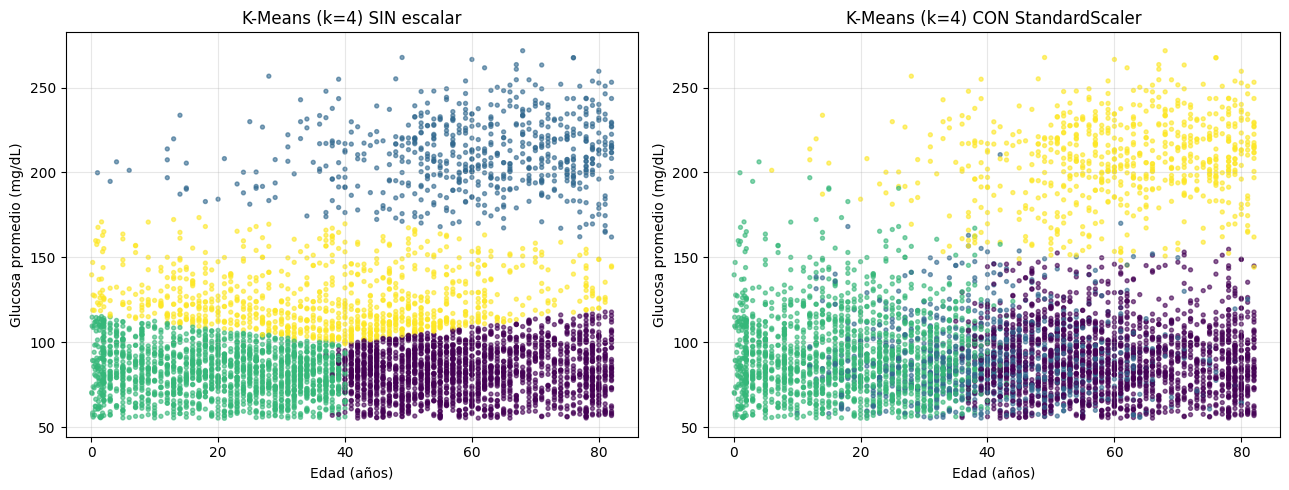

Modelo SIN escalar: rango de edad y glucosa por clúster
         edad_min  edad_max  glucosa_min  glucosa_max
cluster                                              
0            37.0      82.0         55.2        117.8
1             1.0      82.0        162.0        271.7
2             0.1      40.0         55.1        115.1
3             0.1      82.0         99.0        173.4

Varianza de cada variable (sin escalar):
age                   511.4
avg_glucose_level    2050.7
bmi                    59.3
dtype: float64


In [ ]:
# Experimento: K-Means con k=4 SIN escalar vs CON escalar
km_raw = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X)
km_std = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, km, titulo in [(axes[0], km_raw, 'SIN escalar'), (axes[1], km_std, 'CON StandardScaler')]:
    ax.scatter(X['age'], X['avg_glucose_level'], c=km.labels_, cmap='viridis', s=8, alpha=0.6)
    ax.set_title(f'K-Means (k=4) {titulo}')
    ax.set_xlabel('Edad (años)')
    ax.set_ylabel('Glucosa promedio (mg/dL)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Rango de edad dentro de cada clúster en el modelo sin escalar
print('Modelo SIN escalar: rango de edad y glucosa por clúster')
print(X.assign(cluster=km_raw.labels_).groupby('cluster').agg(
    edad_min=('age', 'min'), edad_max=('age', 'max'),
    glucosa_min=('avg_glucose_level', 'min'), glucosa_max=('avg_glucose_level', 'max')).round(1))

# Varianza de cada variable: cuánto 'pesa' en la distancia euclidiana sin escalar
print()
print('Varianza de cada variable (sin escalar):')
print(X.var().round(1))

**Interpretación:** sin escalar, los dos clústeres de glucosa alta (amarillo y azul en la gráfica izquierda) son franjas **horizontales** que abarcan desde bebés hasta 82 años: ahí la edad no cuenta. Además, el IMC (σ ≈ 7.7) queda prácticamente ignorado, porque su varianza es ~35 veces menor que la de la glucosa (σ ≈ 45.3). En este dataset la diferencia de escalas es "solo" de 2 a 6 veces y aun así distorsiona los grupos; con escalas más dispares (por ejemplo, ingresos en pesos junto a edad en años) el algoritmo agruparía por una sola variable y el resultado sería inútil. Con escalado, los grupos combinan edad, glucosa e IMC, que es lo que buscamos para describir perfiles de pacientes.

---
## Sección 2: Búsqueda del número óptimo de clústeres
Entrenamos K-Means para $k = 1, \dots, 10$ y guardamos:
- **Inercia** (WCSS): suma de distancias al cuadrado de cada punto a su centroide. Siempre baja al aumentar $k$; buscamos el "codo" donde deja de bajar mucho.
- **Coeficiente de silueta**: para cada punto compara la distancia media a su propio clúster ($a$) contra la del clúster vecino más cercano ($b$): $s = \frac{b - a}{\max(a, b)}$. Va de −1 a 1; más alto = grupos más compactos y separados. No está definido para $k = 1$.

In [ ]:
k_values = range(1, 11)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels) if k > 1 else np.nan)

resultados_k = pd.DataFrame({'k': list(k_values), 'inercia': inertias, 'silueta': silhouettes})
resultados_k['reducción inercia (%)'] = (-resultados_k['inercia'].pct_change() * 100)
resultados_k.round(3)

,k,inercia,silueta,reducción inercia (%)
0,1,15327.000,NaN,NaN
1,2,10384.687,0.300,32.246
2,3,6811.878,0.371,34.405
3,4,5138.563,0.373,24.565
4,5,4385.336,0.324,14.658
5,6,3977.978,0.312,9.289
6,7,3609.331,0.285,9.267
7,8,3312.974,0.272,8.211
8,9,3042.596,0.288,8.161
9,10,2806.752,0.278,7.751


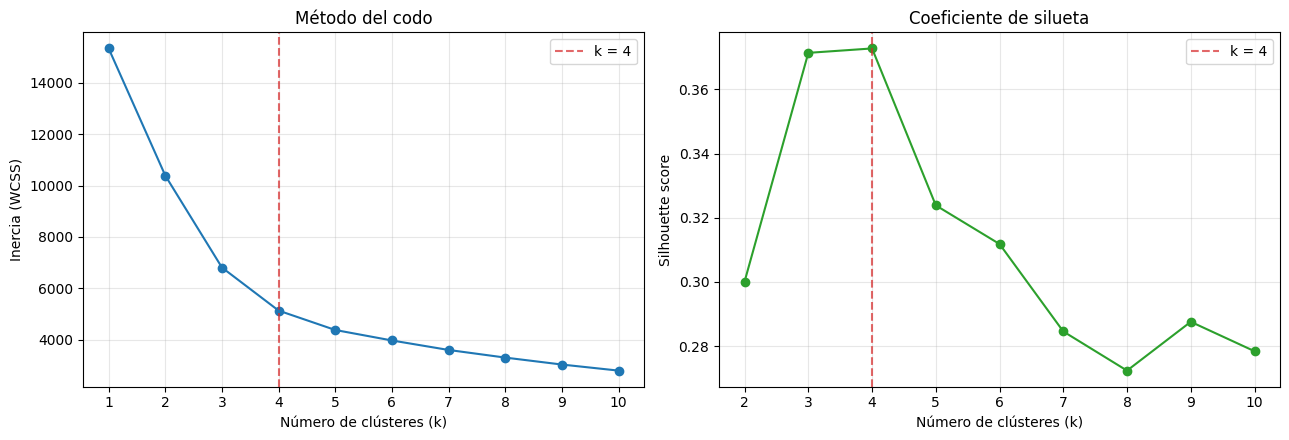

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_values), inertias, 'o-', color='tab:blue')
axes[0].axvline(4, color='tab:red', ls='--', alpha=0.7, label='k = 4')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].set_xticks(list(k_values))
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(list(k_values)[1:], silhouettes[1:], 'o-', color='tab:green')
axes[1].axvline(4, color='tab:red', ls='--', alpha=0.7, label='k = 4')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('Número de clústeres (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_xticks(list(k_values)[1:])
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
k_optimo = int(resultados_k.loc[resultados_k['silueta'].idxmax(), 'k'])
print('k con mayor silueta:', k_optimo, '->', round(resultados_k['silueta'].max(), 3))

k con mayor silueta: 4 -> 0.373


### Selección de $k$
- **Codo:** la inercia cae fuerte de $k=1$ a $k=4$ (≈ 32 %, 34 % y 25 % en cada paso) y a partir de $k=5$ las reducciones son mucho menores (15 % y menos). El codo se ubica entre $k=3$ y $k=4$.
- **Silueta:** el máximo se alcanza en **$k=4$ (0.373)**, prácticamente empatado con $k=3$ (0.371); desde $k=5$ baja claramente.

Ambos criterios coinciden, así que elegimos **$k = 4$ perfiles de pacientes**: es el valor con mejor separación y, frente a $k=3$, reduce la inercia otro 25 %, lo que permite distinguir un perfil adicional.

---
## Sección 3: Entrenamiento del modelo final y centroides

In [ ]:
K_FINAL = 4
kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE)
clusters = kmeans.fit_predict(X_scaled)

print('Inercia final  :', round(kmeans.inertia_, 2))
print('Silueta final  :', round(silhouette_score(X_scaled, clusters), 3))
print('Pacientes por clúster:')
print(pd.Series(clusters).value_counts().sort_index())

Inercia final  : 5138.56
Silueta final  : 0.373
Pacientes por clúster:
0    1877
1     922
2    1638
3     672
Name: count, dtype: int64


### 3.2 Coordenadas de los centroides
`kmeans.cluster_centers_` está en la escala estandarizada (z-scores). Con `scaler.inverse_transform()` los regresamos a unidades reales para poder interpretarlos.

In [ ]:
centroides_z = pd.DataFrame(kmeans.cluster_centers_, columns=features)
centroides_z.index.name = 'cluster'
print('Centroides en escala estandarizada (z-score):')
centroides_z.round(3)

Centroides en escala estandarizada (z-score):


,age,avg_glucose_level,bmi
cluster,,,
0,0.743,-0.367,-0.146
1,-0.075,-0.349,1.320
2,-1.121,-0.298,-0.787
3,0.766,2.234,0.505


In [ ]:
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroides.index.name = 'cluster'
centroides['n_pacientes'] = pd.Series(clusters).value_counts().sort_index()
print('Centroides en unidades originales:')
centroides.round(2)

Centroides en unidades originales:


,age,avg_glucose_level,bmi,n_pacientes
cluster,,,,
0,60.03,89.54,27.74,1877
1,41.52,90.32,39.03,922
2,17.88,92.64,22.81,1638
3,60.54,207.30,32.75,672


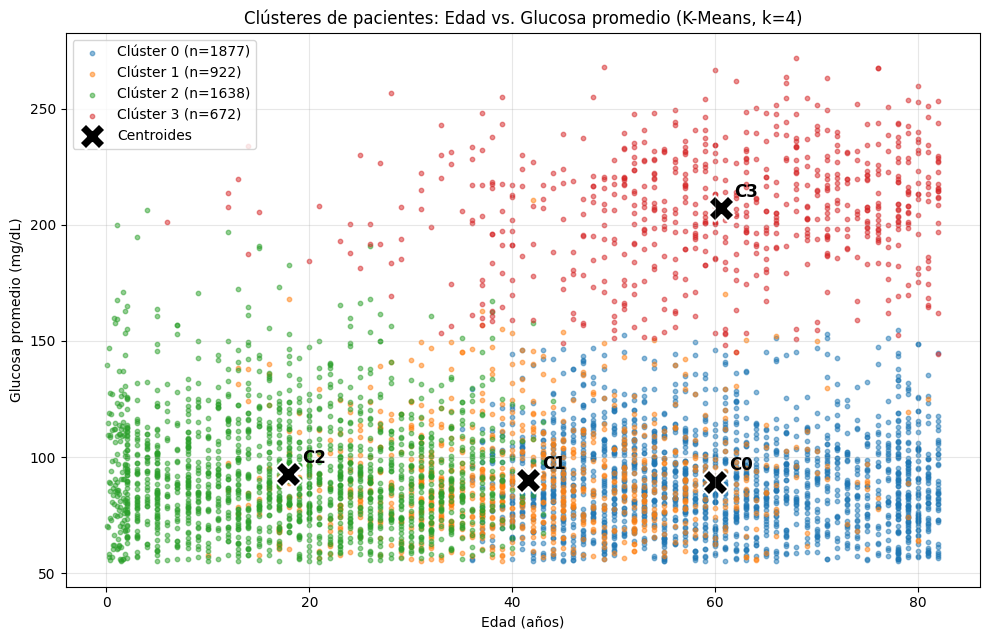

In [ ]:
# Gráfico de dispersión Edad vs. Glucosa con centroides
colores = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

fig, ax = plt.subplots(figsize=(10, 6.5))
for c in range(K_FINAL):
    m = clusters == c
    ax.scatter(X.loc[m, 'age'], X.loc[m, 'avg_glucose_level'], s=10, alpha=0.5,
               color=colores[c], label=f'Clúster {c} (n={m.sum()})')
ax.scatter(centroides['age'], centroides['avg_glucose_level'], marker='X', s=350,
           c='black', edgecolors='white', linewidths=1.5, label='Centroides')
for c in range(K_FINAL):
    ax.annotate(f'C{c}', (centroides.loc[c, 'age'], centroides.loc[c, 'avg_glucose_level']),
                xytext=(10, 8), textcoords='offset points', fontsize=12, fontweight='bold')
ax.set_title('Clústeres de pacientes: Edad vs. Glucosa promedio (K-Means, k=4)')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Glucosa promedio (mg/dL)')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

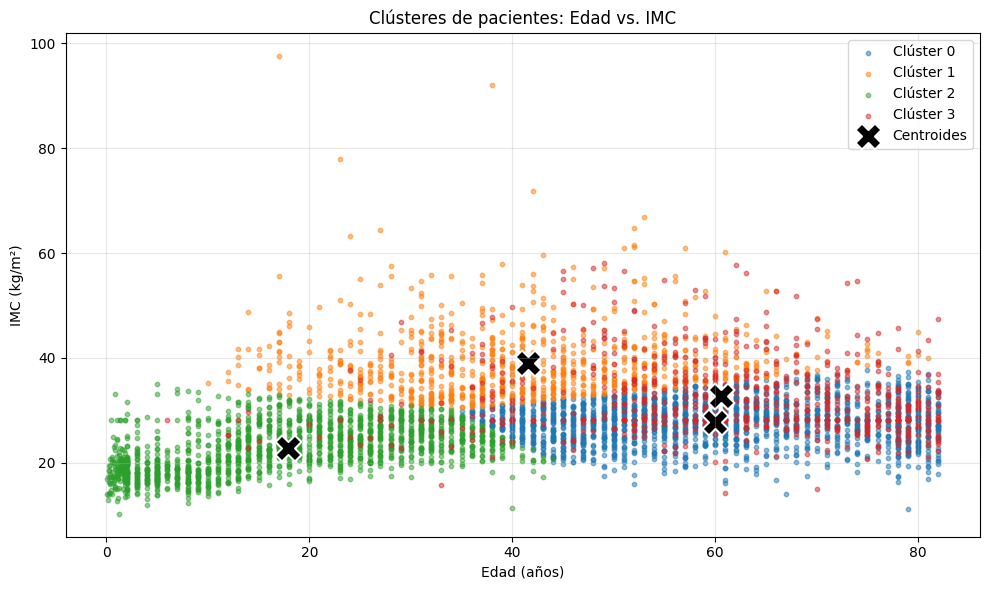

In [ ]:
# Vista complementaria: Edad vs. IMC
fig, ax = plt.subplots(figsize=(10, 6))
for c in range(K_FINAL):
    m = clusters == c
    ax.scatter(X.loc[m, 'age'], X.loc[m, 'bmi'], s=10, alpha=0.5, color=colores[c], label=f'Clúster {c}')
ax.scatter(centroides['age'], centroides['bmi'], marker='X', s=350, c='black',
           edgecolors='white', linewidths=1.5, label='Centroides')
ax.set_title('Clústeres de pacientes: Edad vs. IMC')
ax.set_xlabel('Edad (años)'); ax.set_ylabel('IMC (kg/m²)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación de los perfiles
Los números exactos están en la tabla de centroides; la lectura de cada grupo es:

| Clúster | Perfil | Edad | Glucosa | IMC |
|---|---|---|---|---|
| **0** | Adultos mayores con glucosa normal | ≈ 60 años | ≈ 90 mg/dL (normal) | ≈ 27.7 (sobrepeso) |
| **1** | Adultos de mediana edad con obesidad | ≈ 42 años | ≈ 90 mg/dL (normal) | ≈ 39 (obesidad) |
| **2** | Niños, adolescentes y adultos jóvenes | ≈ 18 años | ≈ 93 mg/dL (normal) | ≈ 22.8 (normal) |
| **3** | Adultos mayores con hiperglucemia | ≈ 61 años | ≈ 207 mg/dL (rango diabético) | ≈ 32.8 (obesidad) |

Las dos variables que más separan a los grupos son la edad (jóvenes vs. mayores) y la glucosa (normal vs. muy alta). El IMC separa a los adultos con obesidad (clúster 1).

---
## Sección 4: Validación cruzada con la etiqueta real
### 4.1 Volver a unir `stroke` con los clústeres

In [ ]:
df_resultado = X.copy()
df_resultado['cluster'] = clusters
df_resultado['stroke'] = y_stroke.values
df_resultado.head()

,age,avg_glucose_level,bmi,cluster,stroke
0,67.0,228.69,36.6,3,1
1,61.0,202.21,28.1,3,1
2,80.0,105.92,32.5,0,1
3,49.0,171.23,34.4,3,1
4,79.0,174.12,24.0,3,1


### 4.2 Tabla cruzada clúster × stroke

In [ ]:
tabla_conteos = pd.crosstab(df_resultado['cluster'], df_resultado['stroke'],
                            margins=True, margins_name='Total')
tabla_conteos.columns = ['Sin stroke (0)', 'Con stroke (1)', 'Total']
tabla_conteos

,Sin stroke (0),Con stroke (1),Total
cluster,,,
0,1736,141,1877
1,907,15,922
2,1634,4,1638
3,583,89,672
Total,4860,249,5109


In [ ]:
# Proporción de stroke dentro de cada clúster (normalizado por fila)
tabla_pct = pd.crosstab(df_resultado['cluster'], df_resultado['stroke'], normalize='index') * 100
tabla_pct.columns = ['% sin stroke', '% con stroke']

# Qué parte del total de casos de stroke cae en cada clúster
tabla_pct['% del total de casos'] = (pd.crosstab(df_resultado['cluster'], df_resultado['stroke'],
                                                 normalize='columns')[1] * 100)
# Riesgo relativo frente a la tasa general del dataset
tasa_general = y_stroke.mean() * 100
tabla_pct['riesgo relativo'] = tabla_pct['% con stroke'] / tasa_general

print(f'Tasa general de stroke en el dataset: {tasa_general:.2f} %')
tabla_pct.round(2)

Tasa general de stroke en el dataset: 4.87 %


,% sin stroke,% con stroke,% del total de casos,riesgo relativo
cluster,,,,
0,92.49,7.51,56.63,1.54
1,98.37,1.63,6.02,0.33
2,99.76,0.24,1.61,0.05
3,86.76,13.24,35.74,2.72


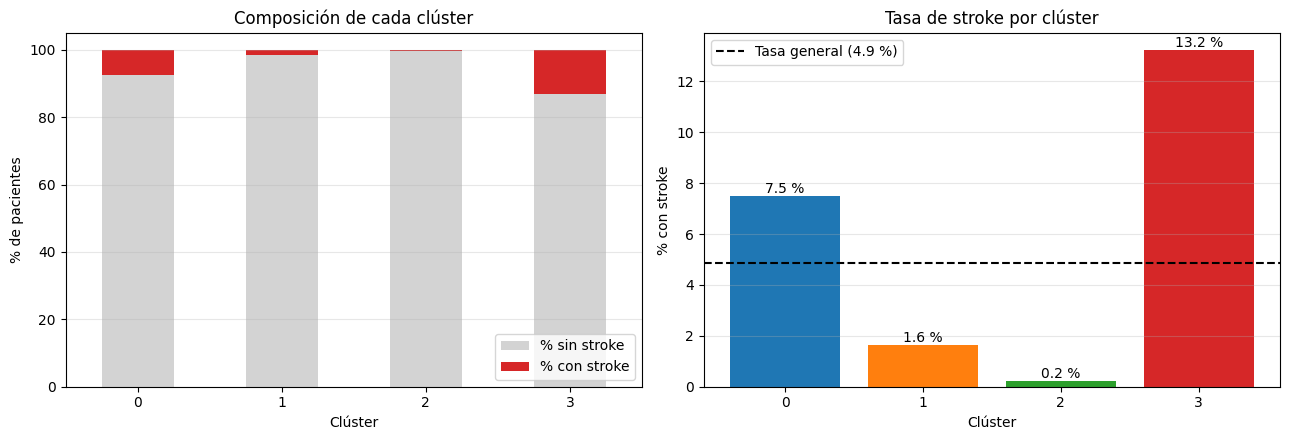

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

tabla_pct[['% sin stroke', '% con stroke']].plot(kind='bar', stacked=True, ax=axes[0],
                                                color=['lightgray', 'tab:red'])
axes[0].set_title('Composición de cada clúster')
axes[0].set_xlabel('Clúster'); axes[0].set_ylabel('% de pacientes')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(loc='lower right')

barras = axes[1].bar(tabla_pct.index.astype(str), tabla_pct['% con stroke'], color=colores)
axes[1].axhline(tasa_general, color='black', ls='--', label=f'Tasa general ({tasa_general:.1f} %)')
axes[1].bar_label(barras, fmt='%.1f %%')
axes[1].set_title('Tasa de stroke por clúster')
axes[1].set_xlabel('Clúster'); axes[1].set_ylabel('% con stroke')
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [ ]:
# Perfil completo: centroides + tasa de stroke
perfil = centroides.copy()
perfil['% stroke'] = tabla_pct['% con stroke']
perfil['casos stroke'] = pd.crosstab(df_resultado['cluster'], df_resultado['stroke'])[1]
perfil.sort_values('% stroke', ascending=False).round(2)

,age,avg_glucose_level,bmi,n_pacientes,% stroke,casos stroke
cluster,,,,,,
3,60.54,207.30,32.75,672,13.24,89
0,60.03,89.54,27.74,1877,7.51,141
1,41.52,90.32,39.03,922,1.63,15
2,17.88,92.64,22.81,1638,0.24,4


### 4.3 Análisis final
**¿Qué clúster concentra el mayor porcentaje de casos de derrame?**
El **clúster 3** (adultos mayores, ≈ 61 años, con glucosa promedio ≈ 207 mg/dL e IMC ≈ 33) tiene una tasa de stroke de **≈ 13.2 %**, es decir, **≈ 2.7 veces la tasa general** del dataset (4.87 %). Le sigue el **clúster 0** (adultos mayores con glucosa normal) con ≈ 7.5 %; por ser el grupo más grande, este último reúne más casos en número absoluto (141 frente a 89), pero el clúster 3 es el de mayor **concentración**. En el extremo opuesto, el clúster 2 (jóvenes, glucosa e IMC normales) tiene apenas ≈ 0.2 %: solo 4 casos entre más de 1,800 pacientes.

Además, los dos clústeres de adultos mayores (0 y 3) reúnen **230 de los 249 casos (≈ 92 %)** de stroke, aunque representan la mitad de los pacientes.

**¿El algoritmo logró aislar un grupo de alto riesgo sin ver la etiqueta?**
**Sí, de forma parcial pero clara.** K-Means nunca vio la columna `stroke`; solo agrupó por similitud en edad, glucosa e IMC. Aun así, separó un grupo con casi 3 veces el riesgo promedio y otro con riesgo casi nulo, lo que confirma que estas variables fisiológicas contienen información real sobre el riesgo de derrame (coincide con lo observado en el EDA de la Actividad 1: edad y glucosa son los factores más asociados).

**Limitaciones:**
- Incluso en el clúster de mayor riesgo, ~87 % de los pacientes **no** sufrió un derrame. El clustering identifica **perfiles de riesgo**, no predice casos individuales; para eso se necesita un modelo supervisado.
- K-Means asume grupos esféricos y de tamaño similar, y los datos reales forman una nube continua (la silueta de 0.37 indica una estructura moderada, no grupos totalmente separados).
- Solo se usaron 3 variables continuas; factores como hipertensión o enfermedad cardíaca no participaron en el agrupamiento.